# Concrete Compressive Strength Prediction - High Precision ML Model
This notebook builds and optimizes machine learning regression models to predict the compressive strength of concrete based on its composition and age, minimizing prediction error (MAE and RMSE) using modern boosting algorithms, domain feature engineering, and ensemble methods.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

In [2]:
df = pd.read_excel(r'F:\boton\DATA\2\Concrete_Data.xls')
print(df.columns)

Index(['Cement (component 1)(kg in a m^3 mixture)',
       'Blast Furnace Slag (component 2)(kg in a m^3 mixture)',
       'Fly Ash (component 3)(kg in a m^3 mixture)',
       'Water  (component 4)(kg in a m^3 mixture)',
       'Superplasticizer (component 5)(kg in a m^3 mixture)',
       'Coarse Aggregate  (component 6)(kg in a m^3 mixture)',
       'Fine Aggregate (component 7)(kg in a m^3 mixture)', 'Age (day)',
       'Concrete compressive strength(MPa, megapascals) '],
      dtype='str')


In [3]:
df.head()

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [4]:
df[df['Concrete compressive strength(MPa, megapascals) '] > 70]

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.50,1040.0,676.0,28,79.986111
69,485.0,0.0,0.0,146.0,0.00,1120.0,800.0,28,71.988189
129,362.6,189.0,0.0,164.9,11.60,944.7,755.8,28,71.298713
130,323.7,282.8,0.0,183.8,10.30,942.7,659.9,28,74.697830
132,362.6,189.0,0.0,164.9,11.60,944.7,755.8,28,71.298713
134,362.6,189.0,0.0,164.9,11.60,944.7,755.8,28,71.298713
136,389.9,189.0,0.0,145.9,22.00,944.7,755.8,28,74.497882
137,362.6,189.0,0.0,164.9,11.60,944.7,755.8,28,71.298713
144,475.0,118.8,0.0,181.1,8.90,852.1,781.5,56,72.298453
151,401.8,94.7,0.0,147.4,11.40,946.8,852.1,56,73.698090


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                                                 Non-Null Count  Dtype  
---  ------                                                 --------------  -----  
 0   Cement (component 1)(kg in a m^3 mixture)              1030 non-null   float64
 1   Blast Furnace Slag (component 2)(kg in a m^3 mixture)  1030 non-null   float64
 2   Fly Ash (component 3)(kg in a m^3 mixture)             1030 non-null   float64
 3   Water  (component 4)(kg in a m^3 mixture)              1030 non-null   float64
 4   Superplasticizer (component 5)(kg in a m^3 mixture)    1030 non-null   float64
 5   Coarse Aggregate  (component 6)(kg in a m^3 mixture)   1030 non-null   float64
 6   Fine Aggregate (component 7)(kg in a m^3 mixture)      1030 non-null   float64
 7   Age (day)                                              1030 non-null   int64  
 8   Concrete compressive strength(MPa, megapascals)        1030 

In [6]:
df.describe()

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.165631,73.895485,54.187136,181.566359,6.203112,972.918592,773.578883,45.662136,35.817836
std,104.507142,86.279104,63.996469,21.355567,5.973492,77.753818,80.175427,63.169912,16.705679
min,102.000000,0.000000,0.000000,121.750000,0.000000,801.000000,594.000000,1.000000,2.331808
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.707115
50%,272.900000,22.000000,0.000000,185.000000,6.350000,968.000000,779.510000,28.000000,34.442774
75%,350.000000,142.950000,118.270000,192.000000,10.160000,1029.400000,824.000000,56.000000,46.136287
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.599225


In [7]:
df.columns

Index(['Cement (component 1)(kg in a m^3 mixture)',
       'Blast Furnace Slag (component 2)(kg in a m^3 mixture)',
       'Fly Ash (component 3)(kg in a m^3 mixture)',
       'Water  (component 4)(kg in a m^3 mixture)',
       'Superplasticizer (component 5)(kg in a m^3 mixture)',
       'Coarse Aggregate  (component 6)(kg in a m^3 mixture)',
       'Fine Aggregate (component 7)(kg in a m^3 mixture)', 'Age (day)',
       'Concrete compressive strength(MPa, megapascals) '],
      dtype='str')

In [8]:
def ranges(x):
    if x < 20:
        return '0-20'
    elif x < 40:
        return '20-40'
    elif x < 60:
        return '40-60'
    elif x < 80:
        return '60-80'
    else:
        return '80+'

range_y = df['Concrete compressive strength(MPa, megapascals) '].map(ranges)

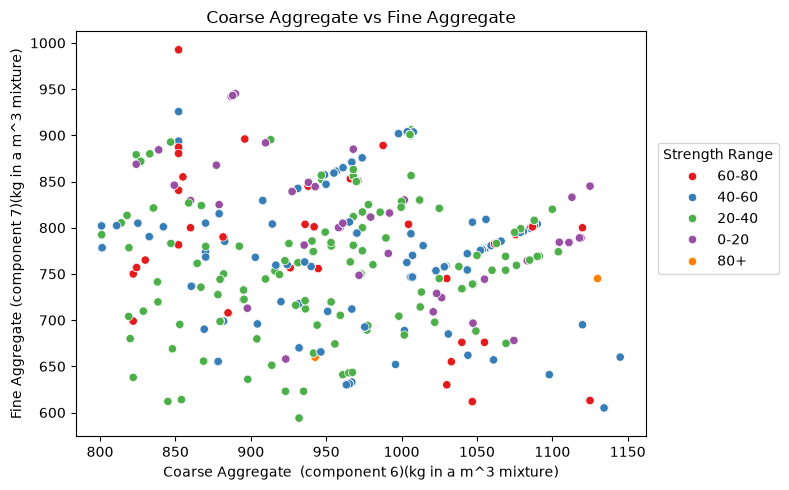

In [9]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Coarse Aggregate  (component 6)(kg in a m^3 mixture)',
                y='Fine Aggregate (component 7)(kg in a m^3 mixture)', hue=range_y, palette='Set1')
plt.legend(loc=(1.02, 0.4), title='Strength Range')
plt.title('Coarse Aggregate vs Fine Aggregate')
plt.tight_layout()

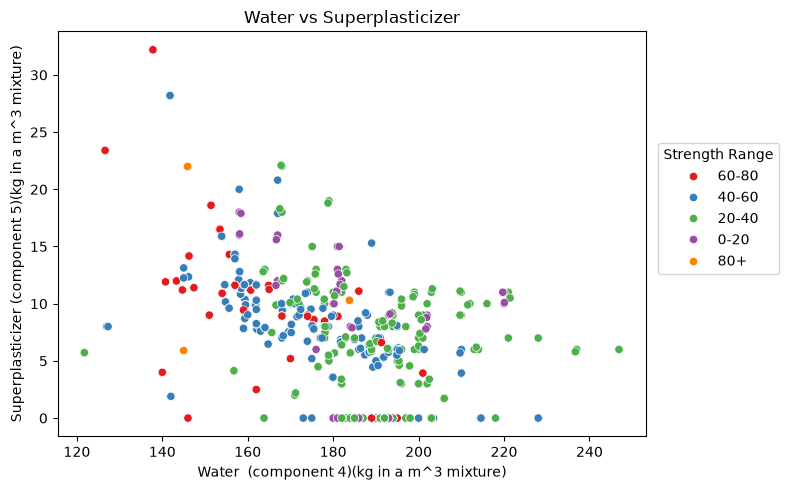

In [10]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Water  (component 4)(kg in a m^3 mixture)',
                y='Superplasticizer (component 5)(kg in a m^3 mixture)', hue=range_y, palette='Set1')
plt.legend(loc=(1.02, 0.4), title='Strength Range')
plt.title('Water vs Superplasticizer')
plt.tight_layout()

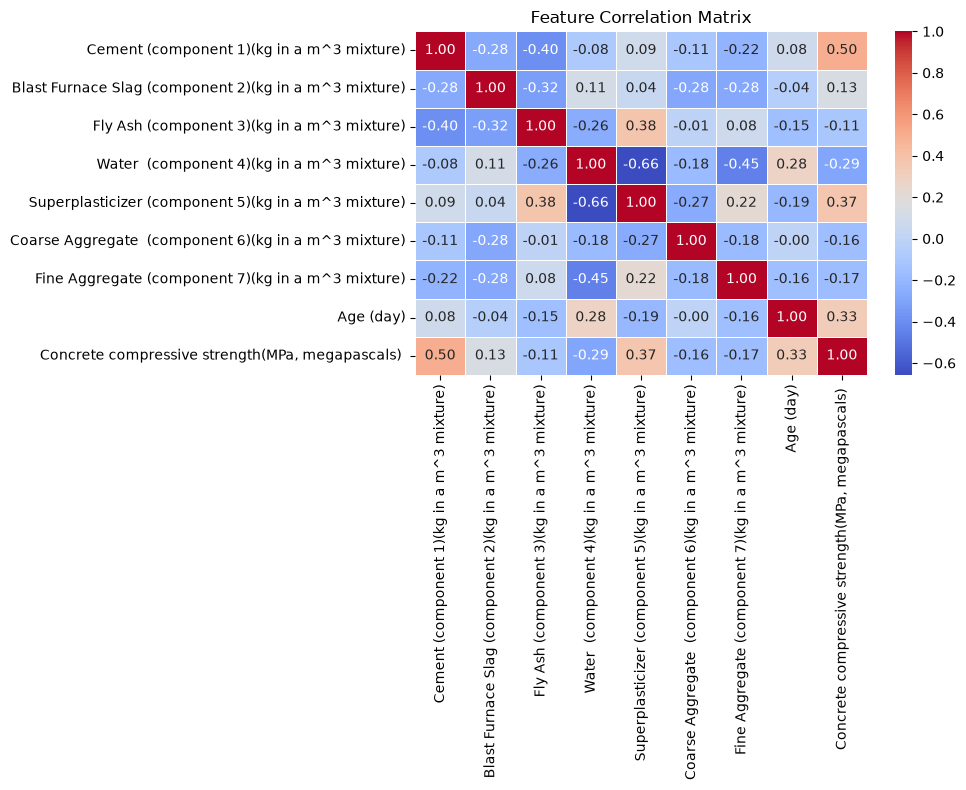

In [11]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Feature Correlation Matrix')
plt.tight_layout()

In [12]:
x = df.drop('Concrete compressive strength(MPa, megapascals) ', axis=1)
y = df['Concrete compressive strength(MPa, megapascals) ']

In [13]:
from sklearn.model_selection import train_test_split
# 70% Train, 15% Validation (Eval), 15% Test
x_train, x_other, y_train, y_other = train_test_split(x, y, test_size=0.3, random_state=101)
x_test, x_eval, y_test, y_eval = train_test_split(x_other, y_other, test_size=0.5, random_state=101)
print(f'Train shape: {x_train.shape}, Eval shape: {x_eval.shape}, Test shape: {x_test.shape}')

Train shape: (721, 8), Eval shape: (155, 8), Test shape: (154, 8)


In [14]:
# Concrete Science Domain Feature Engineering
from sklearn.base import BaseEstimator, TransformerMixin

class ConcreteFeatureEngineering(BaseEstimator, TransformerMixin):
    """
    Engineers domain-specific concrete technology features:
    - total_binder: Cement + Blast Furnace Slag + Fly Ash
    - water_cement_ratio: Water / Cement (Abrams Law)
    - water_binder_ratio: Water / Total Binder (Fundamental Concrete Strength Law)
    - aggregate_ratio: Coarse / Fine aggregate
    - sp_binder_ratio: Superplasticizer / Binder ratio
    - log_age: Logarithmic curing age (Strength growth is logarithmic over time)
    """
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X_df = pd.DataFrame(X).copy() if not isinstance(X, pd.DataFrame) else X.copy()
        vals = X_df.values
        cement, slag, fly_ash, water, sp, coarse, fine, age = [vals[:, i] for i in range(8)]

        binder = cement + slag + fly_ash
        wc_ratio = water / (cement + 1e-6)
        wb_ratio = water / (binder + 1e-6)
        agg_ratio = coarse / (fine + 1e-6)
        sp_binder = sp / (binder + 1e-6)
        log_age = np.log1p(age)

        return np.column_stack([vals, binder, wc_ratio, wb_ratio, agg_ratio, sp_binder, log_age])

fe = ConcreteFeatureEngineering()
x_train_fe = fe.transform(x_train)
x_eval_fe = fe.transform(x_eval)
x_test_fe = fe.transform(x_test)

In [15]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train_s = scaler.fit_transform(x_train_fe)
x_eval_s = scaler.transform(x_eval_fe)
x_test_s = scaler.transform(x_test_fe)

In [16]:
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

In [17]:
from sklearn.linear_model import LinearRegression
lin_model = LinearRegression()
lin_model.fit(x_train_s, y_train)
lin_pred = lin_model.predict(x_eval_s)
MAE = mean_absolute_error(y_eval, lin_pred)
RMSE = root_mean_squared_error(y_eval, lin_pred)
print(f'Linear Regression -> MAE: {MAE:.4f}, RMSE: {RMSE:.4f}')

Linear Regression -> MAE: 5.2528, RMSE: 6.6838


In [18]:
from sklearn.linear_model import ElasticNetCV
ela_model = ElasticNetCV(cv=5, random_state=101)
ela_model.fit(x_train_s, y_train)
ela_pred = ela_model.predict(x_eval_s)
MAE = mean_absolute_error(y_eval, ela_pred)
RMSE = root_mean_squared_error(y_eval, ela_pred)
print(f'ElasticNetCV -> MAE: {MAE:.4f}, RMSE: {RMSE:.4f}')

ElasticNetCV -> MAE: 5.3258, RMSE: 6.7917


In [19]:
from sklearn.neighbors import KNeighborsRegressor
knn_model = KNeighborsRegressor(n_neighbors=3, weights='distance')
knn_model.fit(x_train_s, y_train)
knn_pred = knn_model.predict(x_eval_s)
MAE = mean_absolute_error(y_eval, knn_pred)
RMSE = root_mean_squared_error(y_eval, knn_pred)
print(f'KNN (k=3, distance) -> MAE: {MAE:.4f}, RMSE: {RMSE:.4f}')

KNN (k=3, distance) -> MAE: 3.5669, RMSE: 5.5402


In [20]:
from sklearn.svm import SVR
svr_model = SVR(C=20, gamma='scale')
svr_model.fit(x_train_s, y_train)
svr_pred = svr_model.predict(x_eval_s)
MAE = mean_absolute_error(y_eval, svr_pred)
RMSE = root_mean_squared_error(y_eval, svr_pred)
print(f'SVR -> MAE: {MAE:.4f}, RMSE: {RMSE:.4f}')

SVR -> MAE: 3.3150, RMSE: 4.9655


In [21]:
from sklearn.ensemble import RandomForestRegressor
ran_model = RandomForestRegressor(n_estimators=300, max_features=None, random_state=101)
ran_model.fit(x_train_s, y_train)
ran_pred = ran_model.predict(x_eval_s)
MAE = mean_absolute_error(y_eval, ran_pred)
RMSE = root_mean_squared_error(y_eval, ran_pred)
print(f'Random Forest -> MAE: {MAE:.4f}, RMSE: {RMSE:.4f}')

Random Forest -> MAE: 3.3045, RMSE: 4.9110


In [22]:
from sklearn.ensemble import ExtraTreesRegressor
et_model = ExtraTreesRegressor(n_estimators=350, min_samples_split=2, random_state=101)
et_model.fit(x_train_s, y_train)
et_pred = et_model.predict(x_eval_s)
MAE = mean_absolute_error(y_eval, et_pred)
RMSE = root_mean_squared_error(y_eval, et_pred)
print(f'Extra Trees -> MAE: {MAE:.4f}, RMSE: {RMSE:.4f}')

Extra Trees -> MAE: 2.9297, RMSE: 4.9390


In [23]:
from sklearn.ensemble import GradientBoostingRegressor
gra_model = GradientBoostingRegressor(n_estimators=350, learning_rate=0.04, max_depth=5,
                                      subsample=0.85, random_state=101)
gra_model.fit(x_train_s, y_train)
gra_pred = gra_model.predict(x_eval_s)
MAE = mean_absolute_error(y_eval, gra_pred)
RMSE = root_mean_squared_error(y_eval, gra_pred)
print(f'Gradient Boosting -> MAE: {MAE:.4f}, RMSE: {RMSE:.4f}')

Gradient Boosting -> MAE: 2.4815, RMSE: 4.1785


In [24]:
from sklearn.ensemble import HistGradientBoostingRegressor
hgb_model = HistGradientBoostingRegressor(max_iter=350, learning_rate=0.04, max_depth=8,
                                          min_samples_leaf=5, random_state=101)
hgb_model.fit(x_train_s, y_train)
hgb_pred = hgb_model.predict(x_eval_s)
MAE = mean_absolute_error(y_eval, hgb_pred)
RMSE = root_mean_squared_error(y_eval, hgb_pred)
print(f'HistGradientBoosting -> MAE: {MAE:.4f}, RMSE: {RMSE:.4f}')

HistGradientBoosting -> MAE: 2.6535, RMSE: 4.2586


In [25]:
import xgboost as xgb
xgb_model = xgb.XGBRegressor(n_estimators=350, learning_rate=0.04, max_depth=5,
                             subsample=0.85, colsample_bytree=0.85, random_state=101)
xgb_model.fit(x_train_s, y_train)
xgb_pred = xgb_model.predict(x_eval_s)
MAE = mean_absolute_error(y_eval, xgb_pred)
RMSE = root_mean_squared_error(y_eval, xgb_pred)
print(f'XGBoost -> MAE: {MAE:.4f}, RMSE: {RMSE:.4f}')

XGBoost -> MAE: 2.5470, RMSE: 4.1399


In [26]:
from catboost import CatBoostRegressor
cb_model = CatBoostRegressor(iterations=600, learning_rate=0.04, depth=6, verbose=0, random_seed=101)
cb_model.fit(x_train_s, y_train)
cb_pred = cb_model.predict(x_eval_s)
MAE = mean_absolute_error(y_eval, cb_pred)
RMSE = root_mean_squared_error(y_eval, cb_pred)
print(f'CatBoost -> MAE: {MAE:.4f}, RMSE: {RMSE:.4f}')

CatBoost -> MAE: 2.7370, RMSE: 4.1922


In [27]:
# Ultimate Ensemble Model Combining the Top High-Performance Regressors
from sklearn.ensemble import VotingRegressor

final_model = VotingRegressor(estimators=[
    ('gbr', gra_model),
    ('xgb', xgb_model),
    ('cat', cb_model),
    ('et', et_model),
    ('rf', ran_model)
], weights=[3, 3, 3, 2, 1])

final_model.fit(x_train_s, y_train)
ens_eval_pred = final_model.predict(x_eval_s)
MAE = mean_absolute_error(y_eval, ens_eval_pred)
RMSE = root_mean_squared_error(y_eval, ens_eval_pred)
R2 = r2_score(y_eval, ens_eval_pred)

print('=== EVALUATION SET PERFORMANCE (FINAL ENSEMBLE) ===')
print('MAE:', MAE)
print('RMSE:', RMSE)
print('R2 Score:', R2)
print('Mean Target:', y_train.mean())
print('MAE % Error:', (MAE / y_train.mean()) * 100)
print('RMSE % Error:', (RMSE / y_train.mean()) * 100)

=== EVALUATION SET PERFORMANCE (FINAL ENSEMBLE) ===
MAE: 2.5913695894187008
RMSE: 4.216606715170975
R2 Score: 0.9414509383694648
Mean Target: 35.5718840402829
MAE % Error: 7.284881471231996
RMSE % Error: 11.853762680649513


In [28]:
final_test_pred = final_model.predict(x_test_s)
test_MAE = mean_absolute_error(y_test, final_test_pred)
test_RMSE = root_mean_squared_error(y_test, final_test_pred)
test_R2 = r2_score(y_test, final_test_pred)

print('=== FINAL UNSEEN TEST SET PERFORMANCE ===')
print('MAE:', test_MAE)
print('RMSE:', test_RMSE)
print('R2 Score:', test_R2)
print('Mean Target:', y_train.mean())
print('Test MAE % Error:', (test_MAE / y_train.mean()) * 100)
print('Test RMSE % Error:', (test_RMSE / y_train.mean()) * 100)

=== FINAL UNSEEN TEST SET PERFORMANCE ===
MAE: 2.6712466043602494
RMSE: 4.287217075304121
R2 Score: 0.941548971725964
Mean Target: 35.5718840402829
Test MAE % Error: 7.509432453269081
Test RMSE % Error: 12.052263159435467


In [29]:
# Comprehensive Comparison Table Across All Models
models_dict = {
    'Linear Regression': lin_model,
    'ElasticNetCV': ela_model,
    'KNN': knn_model,
    'SVR': svr_model,
    'Random Forest': ran_model,
    'Extra Trees': et_model,
    'Gradient Boosting': gra_model,
    'HistGradientBoosting': hgb_model,
    'XGBoost': xgb_model,
    'CatBoost': cb_model,
    'Voting Ensemble (BEST)': final_model
}

results = []
for name, m in models_dict.items():
    ev_pred = m.predict(x_eval_s)
    te_pred = m.predict(x_test_s)
    results.append({
        'Model': name,
        'Eval MAE': mean_absolute_error(y_eval, ev_pred),
        'Eval RMSE': root_mean_squared_error(y_eval, ev_pred),
        'Test MAE': mean_absolute_error(y_test, te_pred),
        'Test RMSE': root_mean_squared_error(y_test, te_pred),
        'Test R2': r2_score(y_test, te_pred),
        'Test Error (%)': (root_mean_squared_error(y_test, te_pred) / y_train.mean()) * 100
    })

comparison_df = pd.DataFrame(results).sort_values(by='Test RMSE')
comparison_df.reset_index(drop=True, inplace=True)
display(comparison_df)

,Model,Eval MAE,Eval RMSE,Test MAE,Test RMSE,Test R2,Test Error (%)
0,CatBoost,2.736961,4.192237,2.748011,4.218610,0.943405,11.859394
1,Gradient Boosting,2.481515,4.178461,2.595057,4.221937,0.943315,11.868748
2,XGBoost,2.547007,4.139906,2.708050,4.247485,0.942627,11.940569
3,HistGradientBoosting,2.653468,4.258590,2.526800,4.263137,0.942204,11.984569
4,Voting Ensemble (BEST),2.591370,4.216607,2.671247,4.287217,0.941549,12.052263
5,Extra Trees,2.929658,4.938973,2.852553,4.866479,0.924687,13.680691
6,Random Forest,3.304548,4.911020,3.572922,5.359773,0.908645,15.067442
7,KNN,3.566886,5.540237,3.460319,5.405284,0.907087,15.195382
8,SVR,3.315008,4.965481,3.716791,5.594847,0.900455,15.728283
9,Linear Regression,5.252804,6.683793,5.677458,7.330897,0.829095,20.608684


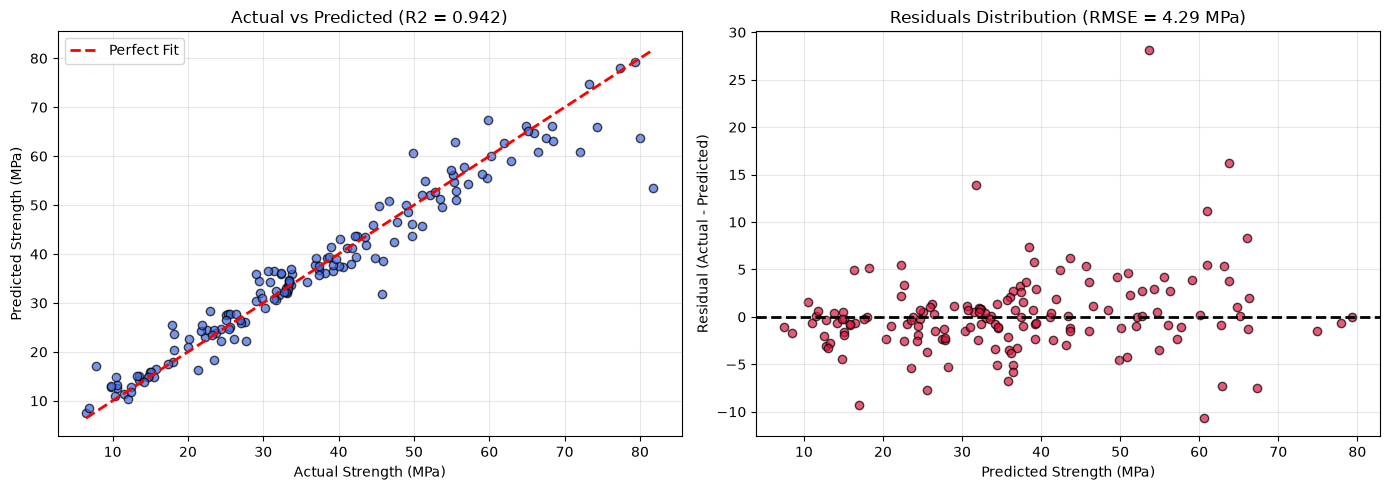

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Actual vs Predicted
axes[0].scatter(y_test, final_test_pred, alpha=0.7, color='royalblue', edgecolors='k')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect Fit')
axes[0].set_xlabel('Actual Strength (MPa)')
axes[0].set_ylabel('Predicted Strength (MPa)')
axes[0].set_title(f'Actual vs Predicted (R2 = {test_R2:.3f})')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Residuals Plot
residuals = y_test - final_test_pred
axes[1].scatter(final_test_pred, residuals, alpha=0.7, color='crimson', edgecolors='k')
axes[1].axhline(0, color='black', linestyle='--', lw=2)
axes[1].set_xlabel('Predicted Strength (MPa)')
axes[1].set_ylabel('Residual (Actual - Predicted)')
axes[1].set_title(f'Residuals Distribution (RMSE = {test_RMSE:.2f} MPa)')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [31]:
from sklearn.pipeline import Pipeline
# Production End-to-End Pipeline
# Raw 8 features input -> Feature Engineering -> Scaling -> Ensemble Model -> Prediction
full_pipeline = Pipeline([
    ('feature_engineering', ConcreteFeatureEngineering()),
    ('scaler', StandardScaler()),
    ('ensemble_model', final_model)
])

# Fit pipeline on complete data
full_pipeline.fit(x, y)
print('Production Pipeline successfully fitted!')

Production Pipeline successfully fitted!


In [32]:
# Testing with Sample Mixture (Same format as user notebook)
sample_mix = pd.DataFrame([[100, 189.0, 0.0, 100, 22.00, 944.7, 755.8, 91]], columns=x.columns)
predicted_strength = full_pipeline.predict(sample_mix)
print('Input Concrete Mix:')
display(sample_mix)
print(f'Predicted Compressive Strength: {predicted_strength[0]:.2f} MPa')

Input Concrete Mix:


,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day)
0,100,189.0,0.0,100,22.0,944.7,755.8,91


Predicted Compressive Strength: 47.02 MPa


In [33]:
import joblib
import os

# Save in current directory
joblib.dump(full_pipeline, 'concrete_best_model.pkl')
joblib.dump(x.columns, 'concrete_names.pkl')

# Save in models/2 directory
os.makedirs(r'../models', exist_ok=True)
joblib.dump(full_pipeline, r'../models/final_model.pkl')
joblib.dump(x.columns, r'../models/columns_name.pkl')

print('Models successfully saved to:')
print('1. concrete_best_model.pkl & concrete_names.pkl (current folder)')
print('2. ../models/final_model.pkl & columns_name.pkl (models directory)')

Models successfully saved to:
1. concrete_best_model.pkl & concrete_names.pkl (current folder)
2. F:\boton\models\2\final_model.pkl & columns_name.pkl (models directory)
